In [38]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

In [ ]:
# read and process dataset

path = r"data\src\conflated_database___2026_03_31__11_14_35.xlsx"

df = pd.read_excel(path, sheet_name="TextReading_Included")
df = df[df.topic.notna()].reset_index(drop=True)
df.topic = df.topic.apply(lambda x: x.split(", "))
df.Year = df.Year.astype(int)

df_model = df[df.topic.apply(lambda x: "Model" in x)].reset_index(drop=True)

print(f"papers -- total: {df.shape[0]}")
print(f"papers -- new generative method : {df_model.shape[0]}")

papers -- total: 72
papers -- new generative method : 65


# MODEL

In [83]:
# preprocessing
def process_model_df(df_model):

    df_model["Discriminative/Generative"] = df_model["Core Generative Paradigm"].apply(lambda x: "Discriminative" if "Discriminative" in x else "Generative")

    df_model["Model"] = \
    df_model["Core Generative Paradigm"].apply(lambda x: 
        "Hybrid: Discriminative" if ("Hybrid" in x and "Discriminative" in x) else 
        (
            "Hybrid: Generative" if "Hybrid" in x else x
        )
    )

    return df_model


# plots
MODEL_COLOR_MAP = {
    'Autoregressive': 'tab:blue',
    'Diffusion': 'tab:orange',
    'Discriminative': 'tab:green',
    'GAN': 'tab:red',
    'Hybrid: Discriminative': 'tab:purple',
    'Hybrid: Generative': 'tab:brown',
    'VAE': 'tab:pink',
}

def plot_discriminative_vs_generative(df_model):
    group_counts = df_model.groupby(['Year', 'Discriminative/Generative']).size().unstack(fill_value=0)
    group_counts = group_counts.sort_index()
    group_counts

    ax = group_counts.plot(
        kind='bar',
        stacked=True,
        rot=0,
        ylabel="# papers"
    )


def plot_model_per_year(df_model):
    model_counts = df_model.groupby(['Year', 'Model']).size().unstack(fill_value=0).sort_index()
    colors = [
        MODEL_COLOR_MAP.get(col, "#cccccc")
        for col in model_counts.columns
    ]

    ax = model_counts.plot(
        kind='bar',
        stacked=True,
        rot=0,
        ylabel="# papers",
        color=colors,
    )


def plot_model(df_model):    
    model_counts = df_model["Model"].value_counts(ascending=True)
    colors = [MODEL_COLOR_MAP[m] for m in model_count.index]

    ax = model_counts.plot(kind="barh", color=colors)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel("# papers")
    ax.set_ylabel("ML model")

In [30]:
df_model = process_model_df(df_model)

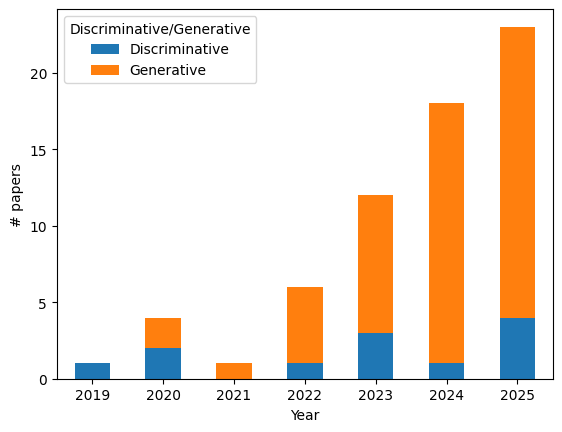

In [35]:
plot_discriminative_vs_generative(df_model)

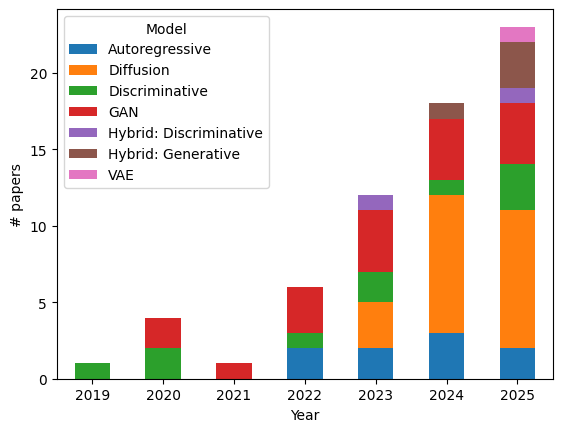

In [84]:
plot_model_per_year(df_model)

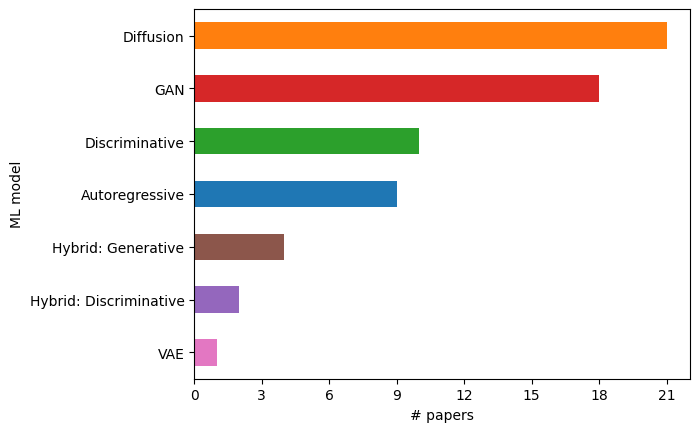

In [78]:
plot_model(df_model)

# PRE PROCESSING